# Palmer Penguins: төрт модельді салыстыру
**Орындаған: Қуат Ақылбек**  
**Пән: Машиналық оқыту**

Мақсат: пингвиннің дене өлшемдері арқылы **Adelie, Chinstrap, Gentoo** түрлерінің бірін болжау және бірдей тест жиынында нәтижелерін салыстыру.

| Жіберілген файл | Осы жұмыстағы модель | Нені болжайды? |
|---|---|---|
| Decision Tree Classification | DecisionTreeClassifier | Пингвин түрі |
| Random Forest | RandomForestClassifier | Пингвин түрі |
| XGBoost | XGBClassifier | Пингвин түрі |
| Decision Tree Regressor | DecisionTreeRegressor + one-hot + argmax | Түрді болжауға бейімделген нұсқа |

**Неліктен бейімдеу қажет?** Regressor сандық мәндерді болжайды. Оған түрлердің `0, 1, 2` кодтарын беріп, нәтижені дөңгелектеу түрлер арасында жоқ реттілікті енгізеді. Сондықтан әр түрге жеке 0/1 бағанын береміз. Үш болжамның ең үлкені түрді анықтайды. Бұл кәдімгі классификатор емес, регрессордың оқу мақсатындағы бейімдеуі. XGBoost файлындағы сатылымға арналған `XGBRegressor` орнына түрді болжауға сәйкес `XGBClassifier` қолданылады.

Соңғы қосымша бөлімде бастапқы регрессия сабақтарына сәйкес **DecisionTreeRegressor және XGBRegressor арқылы дене массасын** болжаймыз. Олардың граммен берілген қатесі классификацияның Accuracy көрсеткішімен араластырылмайды.

**Іске қосу:** Google Colab → File → Upload notebook → осы `.ipynb` файлы → Runtime → Run all. Дайын орындалған нәтижелер осы файлда сақталған.

## 1. Кітапханалар
Керек кітапханалар жоқ болса ғана орнатылады. Нәтижені қайта тексеру үшін төменде қолданылған нұсқалар басылады.

In [1]:
import importlib.util
import subprocess
import sys

packages = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
            "seaborn": "seaborn", "sklearn": "scikit-learn", "xgboost": "xgboost", "IPython": "ipython"}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import io
import json
import hashlib
import platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.utils.validation import check_X_y, check_array, check_is_fitted
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, KFold
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    mean_absolute_error, mean_squared_error, r2_score)
from xgboost import XGBClassifier, XGBRegressor

SEED = 42
OUT = Path("results")
OUT.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", font="DejaVu Sans")
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
COLORS = ["#137C72", "#7956A5", "#D78B32", "#3D79AF"]
VERSIONS = {"python": platform.python_version(), "numpy": np.__version__,
            "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
            "xgboost": xgboost.__version__}
print(VERSIONS)

{'python': '3.12.14', 'numpy': '2.3.5', 'pandas': '2.2.3', 'scikit-learn': '1.8.0', 'xgboost': '3.4.1'}


## 2. Palmer Penguins деректерін жүктеу
Дереккөзі: [Palmer Penguins ресми репозиторийі](https://github.com/allisonhorst/palmerpenguins). Деректерді Kristen Gorman және Palmer Station LTER ұсынған, лицензиясы CC0.

CSV осы notebook-пен бір бумада болса, жергілікті көшірме оқылады. Болмаса ресми CSV жүктеледі.

| Баған | Мағынасы |
|---|---|
| species | Пингвиннің түрі, мақсатты жауап |
| bill_length_mm | Тұмсық ұзындығы, мм |
| bill_depth_mm | Тұмсық тереңдігі, мм |
| flipper_length_mm | Жүзбе қанат ұзындығы, мм |
| body_mass_g | Дене массасы, г |
| island, sex, year | Арал, жыныс, бақылау жылы |

Түрді салыстыру үшін төрт дене өлшемін ғана қолданамыз. Осылайша барлық модельге бірдей сандық белгілер беріледі.

In [2]:
DATA_URL = "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv"
local_csv = Path("penguins.csv")
if local_csv.exists():
    raw_bytes = local_csv.read_bytes()
else:
    import urllib.request
    raw_bytes = urllib.request.urlopen(DATA_URL, timeout=30).read()
    local_csv.write_bytes(raw_bytes)

df = pd.read_csv(io.BytesIO(raw_bytes))
DATA_SHA256 = hashlib.sha256(raw_bytes).hexdigest()
FEATURES = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
assert set(FEATURES + ["species"]).issubset(df.columns)
print("Бастапқы жол саны:", len(df), "| Баған саны:", df.shape[1])
print("CSV SHA256:", DATA_SHA256)
display(df.head())
display(df.isna().sum().rename("Бос мәндер").to_frame())
display(df["species"].value_counts().rename("Пингвин саны").to_frame())

Бастапқы жол саны: 344 | Баған саны: 8
CSV SHA256: f204db2c753b0937caac3cb35258562c14f073e4bbc76be24b4c51ce22767a93


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


,Бос мәндер
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11
year,0


,Пингвин саны
species,
Adelie,152
Gentoo,124
Chinstrap,68


## 3. Деректерді тазалау және бірдей бөлу
Тек пайдаланылатын төрт өлшемі немесе түрі жоқ жолдарды алып тастаймыз. `sex` сияқты пайдаланылмайтын бағандағы бос мән үшін жол жойылмайды.

Бөліну: **80% train, 20% test**, `random_state=42`, `stratify=y`. Төрт модель де дәл осы жолдарды алады. Ағаш модельдеріне StandardScaler қажет емес.

`test` параметр таңдауға берілмейді. Параметрлерді train ішіндегі бес бөліктік кросс-валидация таңдайды.

In [3]:
clean = df.dropna(subset=FEATURES + ["species"]).copy()
print("Алынған жолдар:", len(df) - len(clean))
print("Қалған жолдар:", len(clean))
encoder = LabelEncoder()
y = encoder.fit_transform(clean["species"])
X = clean[FEATURES].copy()
CLASS_NAMES = encoder.classes_.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
assert set(X_train.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_test) == len(clean)
assert set(np.unique(y_train)) == set(np.unique(y_test)) == {0, 1, 2}

split_table = pd.DataFrame({
    "Барлығы": np.bincount(y, minlength=3),
    "Train": np.bincount(y_train, minlength=3),
    "Test": np.bincount(y_test, minlength=3)
}, index=CLASS_NAMES)
display(split_table)
print(f"Train: {len(X_train)}, Test: {len(X_test)}")

train_eda = X_train.assign(species=encoder.inverse_transform(y_train))
display(train_eda.groupby("species")[FEATURES].mean().round(2))
display(X_train.describe().round(2))

Алынған жолдар: 2
Қалған жолдар: 342
Train: 273, Test: 69


,Барлығы,Train,Test
Adelie,151,121,30
Chinstrap,68,54,14
Gentoo,123,98,25


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.93,18.33,189.95,3708.26
Chinstrap,49.02,18.52,196.56,3761.11
Gentoo,47.70,14.89,216.95,5076.28


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,273.00,273.00,273.00,273.00
mean,44.07,17.13,200.95,4209.80
std,5.50,2.01,13.91,800.08
min,33.10,13.10,172.00,2700.00
25%,39.50,15.30,190.00,3550.00
50%,44.90,17.30,197.00,4050.00
75%,48.70,18.70,213.00,4750.00
max,59.60,21.50,231.00,6300.00


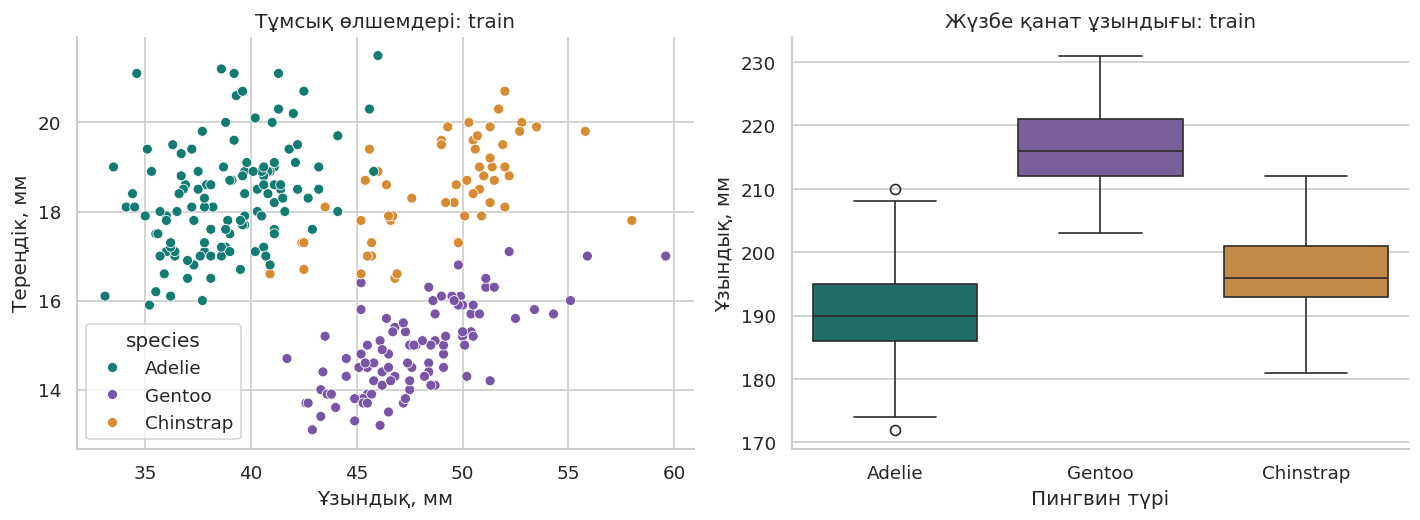

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(data=train_eda, x="bill_length_mm", y="bill_depth_mm",
                hue="species", palette=COLORS[:3], ax=axes[0])
axes[0].set(title="Тұмсық өлшемдері: train", xlabel="Ұзындық, мм", ylabel="Тереңдік, мм")
sns.boxplot(data=train_eda, x="species", y="flipper_length_mm", hue="species",
            palette=COLORS[:3], legend=False, ax=axes[1])
axes[1].set(title="Жүзбе қанат ұзындығы: train", xlabel="Пингвин түрі", ylabel="Ұзындық, мм")
fig.tight_layout()
fig.savefig(OUT / "01_penguins_features.png", bbox_inches="tight")
plt.show()

Графиктер үш түрдің дене өлшемдері әртүрлі таралатынын көрсетеді. Белгілер бір-бірін толықтырады, сондықтан төрт өлшемді бірге қолданамыз. Суреттер тек train деректерінен жасалды.

## 4. Decision Tree Regressor-ды түрді болжауға бейімдеу
Кодтау: Adelie → `[1, 0, 0]`, Chinstrap → `[0, 1, 0]`, Gentoo → `[0, 0, 1]`.

Регрессор бір мезгілде үш бағанды болжайды. Мысалы, `[0.1, 0.8, 0.1]` шықса, ең үлкен мән екінші орында, жауап **Chinstrap** болады. Бірдей ең үлкен мән шықса, `argmax` алғашқы класты таңдайды.

Төмендегі шағын класс осы әрекетті `fit` және `predict` әдістеріне жинайды. Сол арқылы GridSearchCV барлық төрт модельді бірдей Accuracy метрикасымен бағалайды.

**Нәтижелер неге тең болуы мүмкін?** One-hot нысана үшін орташа squared error `Gini / 3` шамасына тең. Сондықтан бірдей тереңдік пен шектеулерде DecisionTreeClassifier және осы бейімделген регрессор бірдей бөлінулер мен нәтижелер беруі мүмкін. Бұл төрт бөлек іске асыру, бірақ төрт тәуелсіз алгоритм отбасы емес.

In [5]:
class OneHotTreeClassifier(ClassifierMixin, BaseEstimator):
    def __init__(self, max_depth=None, min_samples_leaf=1, random_state=42):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.random_state = random_state

    def fit(self, X, y):
        X_array, y_array = check_X_y(X, y)
        self.classes_, class_indices = np.unique(y_array, return_inverse=True)
        self.n_features_in_ = X_array.shape[1]
        one_hot = np.eye(len(self.classes_))[class_indices]
        self.regressor_ = DecisionTreeRegressor(
            criterion="squared_error", max_depth=self.max_depth,
            min_samples_leaf=self.min_samples_leaf, random_state=self.random_state
        )
        self.regressor_.fit(X_array, one_hot)
        return self

    def predict_proba(self, X):
        check_is_fitted(self, "regressor_")
        X_array = check_array(X)
        return self.regressor_.predict(X_array)

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]

## 5. Төрт модель және параметрлер
- **Decision Tree Classifier:** шарттарға бөліп, соңында түрді таңдайды.
- **Random Forest:** көптеген ағаштың класс ықтималдықтарын орташалап, ең жоғарысын таңдайды.
- **XGBoost Classifier:** жаңа ағаштар алдыңғы ансамбльдің қатесін азайтады.
- **Decision Tree Regressor (бейімделген):** үш one-hot бағанын болжайды, ең үлкен мәнді түр ретінде алады.

Әр модельге 8 параметр комбинациясы, әр комбинацияға бірдей 5 fold беріледі. Бірдей комбинация саны толық есептеу бюджеті тең дегенді білдірмейді, бірақ бұл шағын салыстыру үшін алдын ала бекітілген ортақ тәртіп.

`max_depth` ағаш тереңдігін, `min_samples_leaf` жапырақтағы ең аз үлгі санын, `n_estimators` ағаштар санын, `learning_rate` бустинг қадамының үлесін реттейді.

In [6]:
tree_grid = {"max_depth": [2, 3, 4, None], "min_samples_leaf": [1, 2]}
model_specs = {
    "Decision Tree Classifier": (
        DecisionTreeClassifier(criterion="gini", random_state=SEED), tree_grid),
    "Random Forest": (
        RandomForestClassifier(random_state=SEED, n_jobs=1),
        {"n_estimators": [100, 300], "max_depth": [4, None], "min_samples_leaf": [1, 2]}),
    "XGBoost Classifier": (
        XGBClassifier(objective="multi:softprob", num_class=3,
                      eval_metric="mlogloss", tree_method="hist",
                      random_state=SEED, n_jobs=1),
        {"n_estimators": [100, 200], "max_depth": [2, 3], "learning_rate": [0.05, 0.1]}),
    "Decision Tree Regressor (one-hot)": (
        OneHotTreeClassifier(random_state=SEED), tree_grid)
}
cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_train, y_train))
searches = {}
cv_rows = []
for name, (estimator, params) in model_specs.items():
    search = GridSearchCV(estimator, params, cv=cv,
                          scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"},
                          refit="accuracy", n_jobs=1, error_score="raise",
                          return_train_score=True)
    search.fit(X_train, y_train)
    searches[name] = search
    i = search.best_index_
    cv_rows.append({"Модель": name,
                    "CV Accuracy": search.best_score_,
                    "CV std": search.cv_results_["std_test_accuracy"][i],
                    "CV Macro-F1": search.cv_results_["mean_test_f1_macro"][i],
                    "Параметрлер": json.dumps(search.best_params_, ensure_ascii=False)})
    print(name, "| CV:", round(search.best_score_, 4), "|", search.best_params_)
cv_results = pd.DataFrame(cv_rows)
display(cv_results.round(4))
cv_winners = cv_results.loc[np.isclose(cv_results["CV Accuracy"], cv_results["CV Accuracy"].max()), "Модель"].tolist()
print("Тек train-CV бойынша таңдалған үздік модель(дер):", ", ".join(cv_winners))

Decision Tree Classifier | CV: 0.9415 | {'max_depth': 4, 'min_samples_leaf': 1}
Random Forest | CV: 0.9671 | {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 300}
XGBoost Classifier | CV: 0.9708 | {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 200}
Decision Tree Regressor (one-hot) | CV: 0.9415 | {'max_depth': 4, 'min_samples_leaf': 1}
Тек train-CV бойынша таңдалған үздік модель(дер): XGBoost Classifier


,Модель,CV Accuracy,CV std,CV Macro-F1,Параметрлер
0,Decision Tree Classifier,0.9415,0.0176,0.9320,"{""max_depth"": 4, ""min_samples_leaf"": 1}"
1,Random Forest,0.9671,0.0072,0.9602,"{""max_depth"": null, ""min_samples_leaf"": 1, ""n_..."
2,XGBoost Classifier,0.9708,0.0186,0.9650,"{""learning_rate"": 0.05, ""max_depth"": 2, ""n_est..."
3,Decision Tree Regressor (one-hot),0.9415,0.0176,0.9320,"{""max_depth"": 4, ""min_samples_leaf"": 1}"


## 6. Бөлек test жиынында соңғы бағалау
Барлық параметрлер бекітілді. Енді модельдер бұрын көрмеген test пингвиндерінің түрін болжайды.

- **Accuracy:** дұрыс табылған пингвин саны / барлық test пингвиндерінің саны.
- **Macro-F1:** үш түрдің F1 мәндерінің тең салмақты орташа шамасы. Кластар көлемі әртүрлі болғанда пайдалы.
- **Train Accuracy:** модельдің таныс деректердегі ұпайы. Негізгі жеңімпаз осы мәнмен таңдалмайды.
- **Dummy:** барлық үлгіге train-дегі ең жиі түрді айтатын қарапайым бақылау моделі.

Test нәтижелерін көргеннен кейін параметрлерді қайта таңдамау керек.

In [7]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
baseline_accuracy = accuracy_score(y_test, baseline.predict(X_test))
print(f"Қарапайым baseline Accuracy: {baseline_accuracy:.2%}")

predictions, result_rows = {}, []
for name, search in searches.items():
    model = search.best_estimator_
    pred = model.predict(X_test)
    predictions[name] = pred
    result_rows.append({
        "Модель": name,
        "Train Accuracy (%)": 100 * accuracy_score(y_train, model.predict(X_train)),
        "CV Accuracy (%)": 100 * search.best_score_,
        "Test Accuracy (%)": 100 * accuracy_score(y_test, pred),
        "Macro-F1": f1_score(y_test, pred, average="macro", zero_division=0),
        "Дұрыс": int(np.sum(pred == y_test)),
        "Қате": int(np.sum(pred != y_test)),
        "Test саны": len(y_test)
    })
results = pd.DataFrame(result_rows).sort_values(
    ["Test Accuracy (%)", "Macro-F1"], ascending=False, kind="stable").reset_index(drop=True)
display(results.round(3))
results.to_csv(OUT / "classification_comparison.csv", index=False, encoding="utf-8-sig")
cv_results.to_csv(OUT / "cross_validation.csv", index=False, encoding="utf-8-sig")

best_accuracy = results["Test Accuracy (%)"].max()
test_winners = results.loc[np.isclose(results["Test Accuracy (%)"], best_accuracy), "Модель"].tolist()
print("Осы test бойынша ең жоғары Accuracy:", ", ".join(test_winners))
print(f"Дәлдік: {best_accuracy:.2f}%")
print("Тең Accuracy болса, барлық жеңімпаз бірге көрсетіледі.")

Қарапайым baseline Accuracy: 43.48%
Осы test бойынша ең жоғары Accuracy: Decision Tree Classifier, Random Forest, Decision Tree Regressor (one-hot)
Дәлдік: 100.00%
Тең Accuracy болса, барлық жеңімпаз бірге көрсетіледі.


,Модель,Train Accuracy (%),CV Accuracy (%),Test Accuracy (%),Macro-F1,Дұрыс,Қате,Test саны
0,Decision Tree Classifier,98.901,94.148,100.000,1.000,69,0,69
1,Random Forest,100.000,96.707,100.000,1.000,69,0,69
2,Decision Tree Regressor (one-hot),98.901,94.148,100.000,1.000,69,0,69
3,XGBoost Classifier,100.000,97.077,95.652,0.953,66,3,69


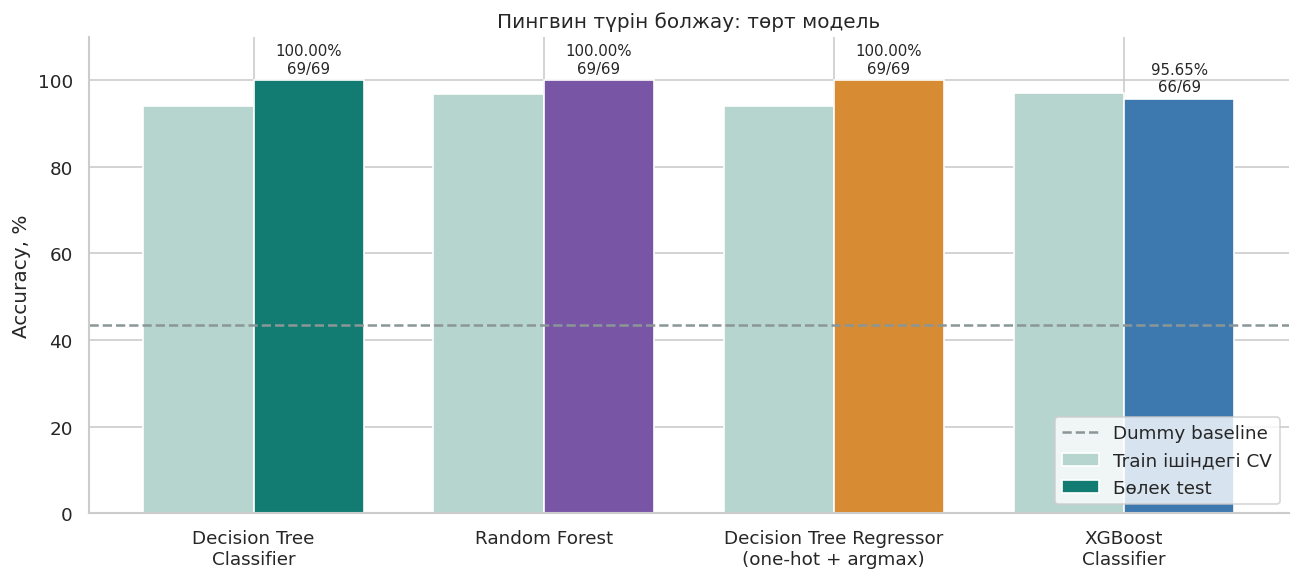

In [8]:
fig, ax = plt.subplots(figsize=(11, 5))
short_names = {"Decision Tree Classifier": "Decision Tree\nClassifier",
               "Random Forest": "Random Forest", "XGBoost Classifier": "XGBoost\nClassifier",
               "Decision Tree Regressor (one-hot)": "Decision Tree Regressor\n(one-hot + argmax)"}
xs = np.arange(len(results))
ax.bar(xs-0.19, results["CV Accuracy (%)"], width=0.38, label="Train ішіндегі CV", color="#B6D5CE")
bars = ax.bar(xs+0.19, results["Test Accuracy (%)"], width=0.38, label="Бөлек test", color=COLORS)
for bar, (_, row) in zip(bars, results.iterrows()):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1,
            f'{row["Test Accuracy (%)"]:.2f}%\n{row["Дұрыс"]}/{row["Test саны"]}',
            ha="center", va="bottom", fontsize=9)
ax.axhline(baseline_accuracy*100, color="#8B9697", linestyle="--", label="Dummy baseline")
ax.set(xticks=xs, xticklabels=[short_names[x] for x in results["Модель"]],
       ylim=(0, 110), yticks=np.arange(0, 101, 20), ylabel="Accuracy, %", title="Пингвин түрін болжау: төрт модель")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(OUT / "02_model_comparison.png", bbox_inches="tight")
plt.show()

## 7. Әр түр бойынша қателер
Қателер матрицасында жолдар нақты түрді, бағандар болжанған түрді көрсетеді. Диагональдағы сандар дұрыс жауаптар.


Decision Tree Classifier
              precision    recall  f1-score   support

      Adelie      1.000     1.000     1.000        30
   Chinstrap      1.000     1.000     1.000        14
      Gentoo      1.000     1.000     1.000        25

    accuracy                          1.000        69
   macro avg      1.000     1.000     1.000        69
weighted avg      1.000     1.000     1.000        69


Random Forest
              precision    recall  f1-score   support

      Adelie      1.000     1.000     1.000        30
   Chinstrap      1.000     1.000     1.000        14
      Gentoo      1.000     1.000     1.000        25

    accuracy                          1.000        69
   macro avg      1.000     1.000     1.000        69
weighted avg      1.000     1.000     1.000        69


XGBoost Classifier
              precision    recall  f1-score   support

      Adelie      0.967     0.967     0.967        30
   Chinstrap      0.875     1.000     0.933        14
      Gentoo  

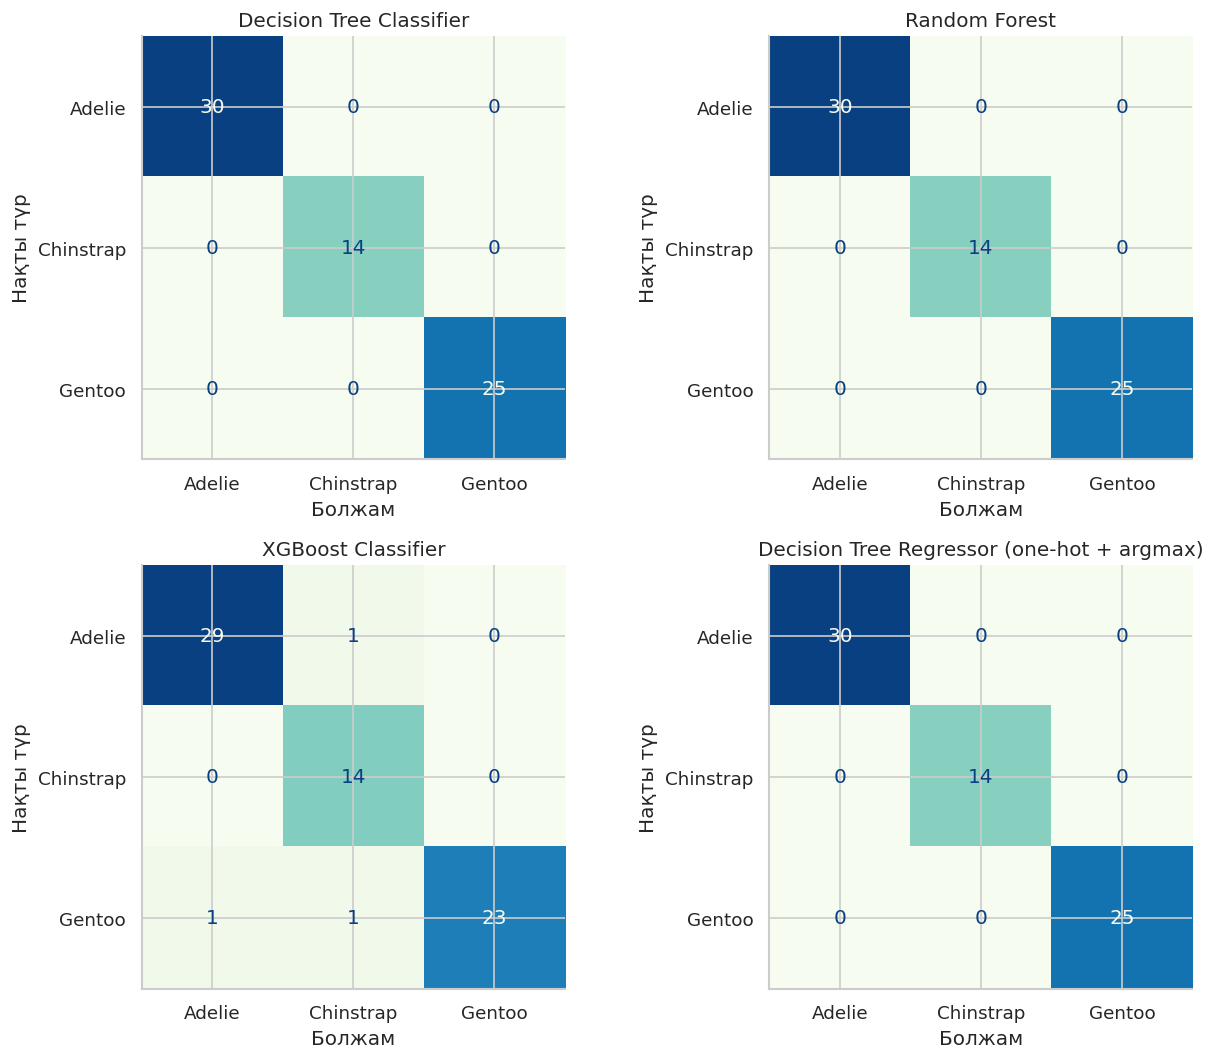

,CSV жолы (тақырыппен),bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,Нақты түр,Decision Tree Classifier,Random Forest,XGBoost Classifier,Decision Tree Regressor (one-hot),Кемінде бір модель қателесті
151,153,41.5,18.5,201.0,4000.0,Adelie,Adelie,Adelie,Adelie,Adelie,False
1,3,39.5,17.4,186.0,3800.0,Adelie,Adelie,Adelie,Adelie,Adelie,False
226,228,46.4,15.0,216.0,4700.0,Gentoo,Gentoo,Gentoo,Gentoo,Gentoo,False
268,270,44.5,15.7,217.0,4875.0,Gentoo,Gentoo,Gentoo,Gentoo,Gentoo,False
282,284,46.1,18.2,178.0,3250.0,Chinstrap,Chinstrap,Chinstrap,Chinstrap,Chinstrap,False
103,105,37.8,20.0,190.0,4250.0,Adelie,Adelie,Adelie,Adelie,Adelie,False
303,305,49.5,19.0,200.0,3800.0,Chinstrap,Chinstrap,Chinstrap,Chinstrap,Chinstrap,False
237,239,50.8,17.3,228.0,5600.0,Gentoo,Gentoo,Gentoo,Chinstrap,Gentoo,True
304,306,46.4,17.8,191.0,3700.0,Chinstrap,Chinstrap,Chinstrap,Chinstrap,Chinstrap,False
297,299,48.5,17.5,191.0,3400.0,Chinstrap,Chinstrap,Chinstrap,Chinstrap,Chinstrap,False


,CSV жолы (тақырыппен),bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,Нақты түр,Decision Tree Classifier,Random Forest,XGBoost Classifier,Decision Tree Regressor (one-hot),Кемінде бір модель қателесті
237,239,50.8,17.3,228.0,5600.0,Gentoo,Gentoo,Gentoo,Chinstrap,Gentoo,True
189,191,44.4,17.3,219.0,5250.0,Gentoo,Gentoo,Gentoo,Adelie,Gentoo,True
131,133,43.1,19.2,197.0,3500.0,Adelie,Adelie,Adelie,Chinstrap,Adelie,True


In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for (name, pred), ax in zip(predictions.items(), axes.flat):
    cm = confusion_matrix(y_test, pred, labels=[0, 1, 2])
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
        ax=ax, cmap="GnBu", colorbar=False, values_format="d")
    ax.set(title=short_names[name].replace("\n", " "), xlabel="Болжам", ylabel="Нақты түр")
fig.tight_layout()
fig.savefig(OUT / "03_confusion_matrices.png", bbox_inches="tight")
plt.show()

for name, pred in predictions.items():
    print("\n" + name)
    print(classification_report(y_test, pred, labels=[0, 1, 2],
                                target_names=CLASS_NAMES, digits=3, zero_division=0))

prediction_table = X_test.copy()
prediction_table.insert(0, "CSV жолы (тақырыппен)", X_test.index+2)
prediction_table["Нақты түр"] = encoder.inverse_transform(y_test)
for name, pred in predictions.items():
    prediction_table[name] = encoder.inverse_transform(pred)
prediction_table["Кемінде бір модель қателесті"] = np.any(
    np.column_stack([p != y_test for p in predictions.values()]), axis=1)
display(prediction_table.head(10))
print("Кемінде бір модель қателескен үлгілер:")
display(prediction_table[prediction_table["Кемінде бір модель қателесті"]])
prediction_table.to_csv(OUT / "test_predictions.csv", index=False, encoding="utf-8-sig")

## 8. Decision Tree-дің құрылымы және тереңдігі
Ағаштың алғашқы үш деңгейін көрсетеміз. Бүкіл ағаш тереңірек болса, суретте тек басы беріледі. Түбірдегі шартты модель өзі таңдаған: ол train деректеріндегі Gini азаюын ең көп арттырған бөліну.

Тереңдікті зерттеу де тек train ішіндегі CV нәтижесімен жасалады.

Түбір шарты: flipper_length_mm <= 206.500
Толық ағаш тереңдігі: 4
Бұл маңыздылық осы модельге қатысты; себеп-салдар байланысын білдірмейді.


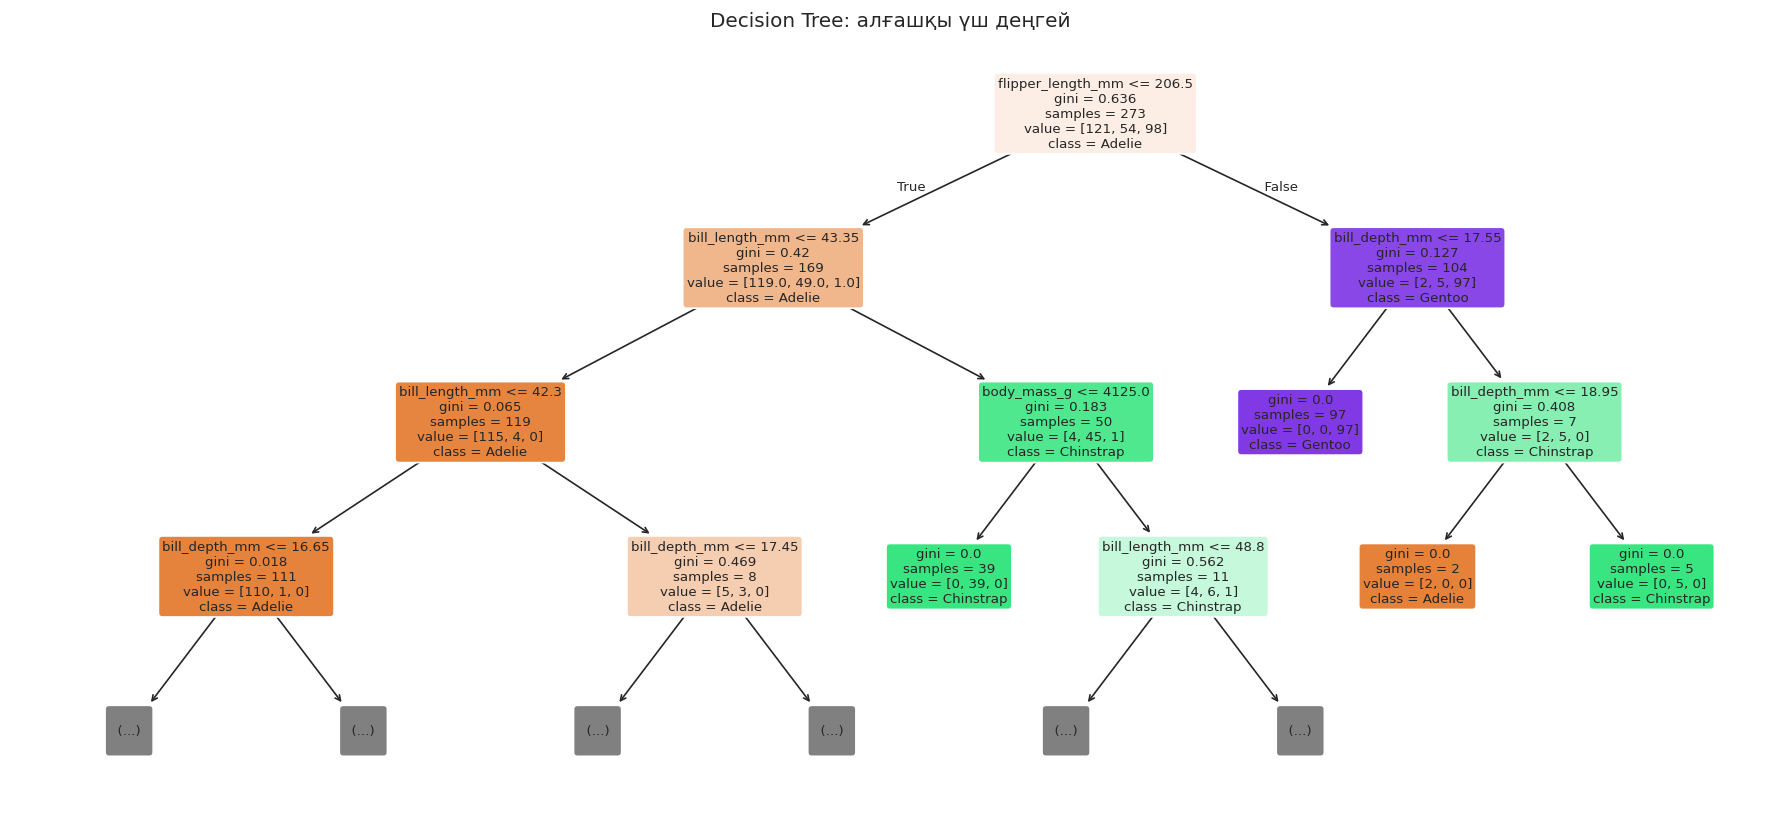

,max_depth,min_samples_leaf,Train fold Accuracy,Validation fold Accuracy
0,2,1,0.9606,0.9341
1,2,2,0.9606,0.9341
2,3,1,0.9744,0.9269
3,3,2,0.9744,0.9269
4,4,1,0.9918,0.9415
5,4,2,0.9881,0.9341
6,None,1,1.0000,0.9305
7,None,2,0.9881,0.9341


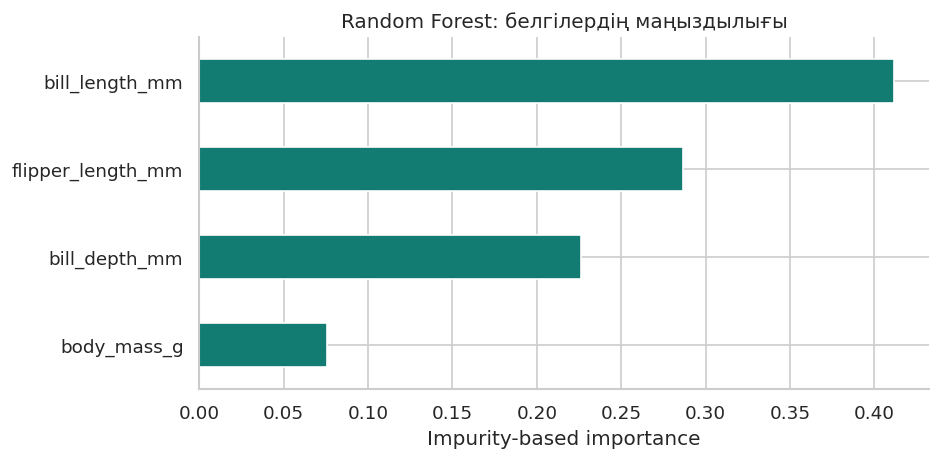

In [10]:
tree_model = searches["Decision Tree Classifier"].best_estimator_
root_feature = FEATURES[tree_model.tree_.feature[0]]
root_threshold = float(tree_model.tree_.threshold[0])
print(f"Түбір шарты: {root_feature} <= {root_threshold:.3f}")
print("Толық ағаш тереңдігі:", tree_model.get_depth())
fig, ax = plt.subplots(figsize=(15, 7))
plot_tree(tree_model, feature_names=FEATURES, class_names=CLASS_NAMES,
          filled=True, rounded=True, max_depth=3, fontsize=8, ax=ax)
ax.set_title("Decision Tree: алғашқы үш деңгей")
fig.tight_layout()
fig.savefig(OUT / "04_decision_tree.png", bbox_inches="tight")
plt.show()

depth_search = pd.DataFrame(searches["Decision Tree Classifier"].cv_results_)
depth_table = depth_search[["param_max_depth", "param_min_samples_leaf", "mean_train_accuracy", "mean_test_accuracy"]].copy()
depth_table.columns = ["max_depth", "min_samples_leaf", "Train fold Accuracy", "Validation fold Accuracy"]
display(depth_table.round(4))

rf = searches["Random Forest"].best_estimator_
importance = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
importance.plot.barh(ax=ax, color=COLORS[0])
ax.set(title="Random Forest: белгілердің маңыздылығы", xlabel="Impurity-based importance", ylabel="")
fig.tight_layout()
fig.savefig(OUT / "05_feature_importance.png", bbox_inches="tight")
plt.show()
print("Бұл маңыздылық осы модельге қатысты; себеп-салдар байланысын білдірмейді.")

## 9. Жаңа пингвинді болжау
Мысал ретінде өлшемдерді өзіміз енгіземіз. Оның нақты түрі белгісіз, сондықтан бұл бөлімге Accuracy есептелмейді. Төрт бағанның атауы мен өлшем бірлігі оқыту деректерімен бірдей болуы керек.

In [11]:
new_penguin = pd.DataFrame([{
    "bill_length_mm": 45.0,
    "bill_depth_mm": 14.5,
    "flipper_length_mm": 215.0,
    "body_mass_g": 5000.0
}], columns=FEATURES)
display(new_penguin)
for name, search in searches.items():
    predicted_class = int(search.best_estimator_.predict(new_penguin)[0])
    print(f"{name}: {CLASS_NAMES[predicted_class]}")

Decision Tree Classifier: Gentoo
Random Forest: Gentoo
XGBoost Classifier: Gentoo
Decision Tree Regressor (one-hot): Gentoo


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,45.0,14.5,215.0,5000.0


## 10. Қосымша: регрессорлар арқылы дене массасын болжау
Бұл бөлімде бастапқы екі регрессия файлының мағынасы сақталады. Мақсатты жауап **body_mass_g**, кіріс белгілері тұмсықтың ұзындығы, тереңдігі және жүзбе қанаттың ұзындығы. Дене массасы кіріске қосылмайды.

Train/test пингвиндері негізгі бөліммен бірдей. Параметрлер тек train ішіндегі 5-fold CV арқылы таңдалады.

- **MAE (г):** абсолют қателердің орташа шамасы. Аз болғаны жақсы.
- **RMSE (г):** квадраттық орташа қатенің түбірі, үлкен қателерге көбірек салмақ береді. Аз болғаны жақсы.
- **R²:** модельдің тұрақты орташа болжаммен салыстырғандағы көрсеткіші. Үлкен болғаны жақсы; пайыздық Accuracy емес.

Осы екі регрессор өзара салыстырылады. Олардың RMSE мәні түрді танудағы Accuracy кестесіне қосылмайды.

Орташа массаны болжайтын baseline RMSE: 809.48 г


,Модель,CV RMSE (г),Test MAE (г),Test RMSE (г),Test R²,Параметрлер
0,XGBoost Regressor,365.716,248.603,309.100,0.854,"{""learning_rate"": 0.05, ""max_depth"": 2, ""n_est..."
1,Decision Tree Regressor,409.626,282.733,354.266,0.808,"{""max_depth"": 4, ""min_samples_leaf"": 2}"


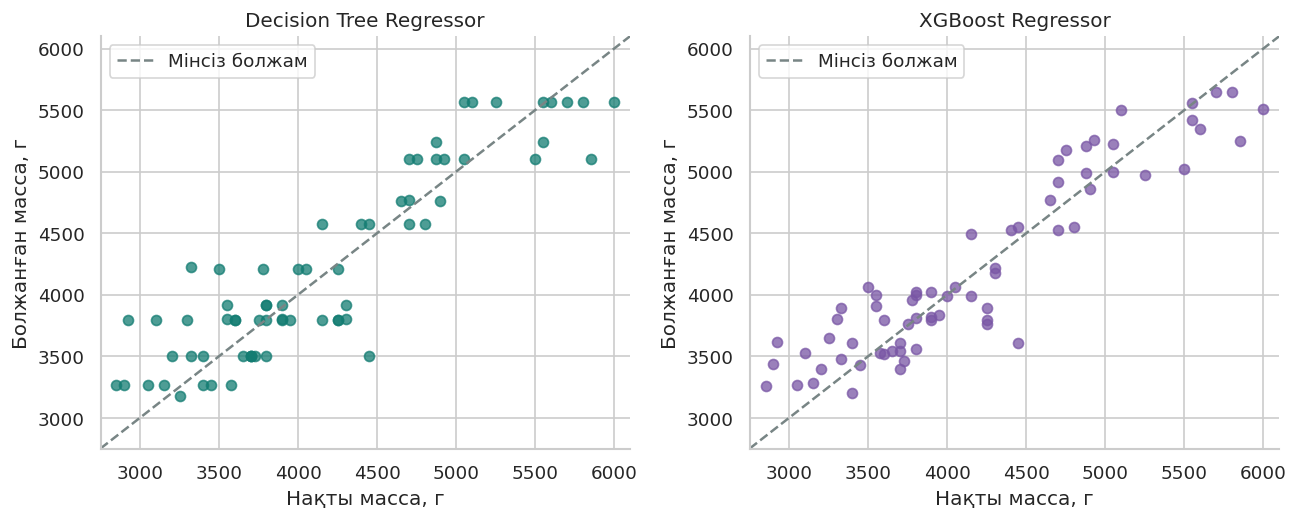

In [12]:
REG_FEATURES = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm"]
RX_train, RX_test = clean.loc[X_train.index, REG_FEATURES], clean.loc[X_test.index, REG_FEATURES]
ry_train, ry_test = clean.loc[X_train.index, "body_mass_g"], clean.loc[X_test.index, "body_mass_g"]
reg_specs = {
    "Decision Tree Regressor": (DecisionTreeRegressor(random_state=SEED), tree_grid),
    "XGBoost Regressor": (XGBRegressor(objective="reg:squarederror", tree_method="hist",
                                      random_state=SEED, n_jobs=1),
                          {"max_depth": [2, 3], "n_estimators": [100, 200], "learning_rate": [0.05, 0.1]})
}
reg_cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
reg_predictions, reg_rows = {}, []
for name, (model, grid) in reg_specs.items():
    search = GridSearchCV(model, grid, cv=reg_cv,
                          scoring="neg_root_mean_squared_error", n_jobs=1, error_score="raise")
    search.fit(RX_train, ry_train)
    pred = search.predict(RX_test)
    reg_predictions[name] = pred
    reg_rows.append({"Модель": name, "CV RMSE (г)": -search.best_score_,
                     "Test MAE (г)": mean_absolute_error(ry_test, pred),
                     "Test RMSE (г)": np.sqrt(mean_squared_error(ry_test, pred)),
                     "Test R²": r2_score(ry_test, pred),
                     "Параметрлер": json.dumps(search.best_params_, ensure_ascii=False)})
reg_results = pd.DataFrame(reg_rows).sort_values("Test RMSE (г)").reset_index(drop=True)
display(reg_results.round(3))
reg_results.to_csv(OUT / "regression_comparison.csv", index=False, encoding="utf-8-sig")
reg_dummy = DummyRegressor().fit(RX_train, ry_train)
print("Орташа массаны болжайтын baseline RMSE:",
      round(np.sqrt(mean_squared_error(ry_test, reg_dummy.predict(RX_test))), 2), "г")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for (name, pred), ax, color in zip(reg_predictions.items(), axes, COLORS[:2]):
    ax.scatter(ry_test, pred, alpha=.75, color=color)
    limits = [min(ry_test.min(), pred.min())-100, max(ry_test.max(), pred.max())+100]
    ax.plot(limits, limits, "--", color="#788585", label="Мінсіз болжам")
    ax.set(title=name, xlabel="Нақты масса, г", ylabel="Болжанған масса, г", xlim=limits, ylim=limits)
    ax.legend()
fig.tight_layout()
fig.savefig(OUT / "06_regression_predictions.png", bbox_inches="tight")
plt.show()

## 11. Нақты нәтижеге сүйенген қорытынды
Төмендегі қорытынды осы іске қосудағы кестеден автоматты түрде жасалады. Test нәтижесінде теңдік болса, барлық тең модель аталады. Бұл шағын бір бөліністегі тәжірибе, модельдің барлық деректерде үздік болуына кепілдік бермейді.

In [13]:
top = results.iloc[0]
best_names = ", ".join(test_winners)
reg_top = reg_results.iloc[0]
summary = (
    f"**Пингвин түрін тану:** {best_names} осы тестте ең жоғары Accuracy көрсетті: "
    f"**{best_accuracy:.2f}%**, яғни {len(y_test)} пингвиннің **{int(top['Дұрыс'])}** түрін дұрыс тапты.\n\n"
    f"Train ішіндегі 5-fold CV бойынша үздік нәтиже: **{', '.join(cv_winners)}**. "
    "CV нәтижесі мен test нәтижесінің реті әртүрлі болуы мүмкін.\n\n"
    f"**Дене массасын болжау:** ең аз test RMSE көрсеткен модель — **{reg_top['Модель']}**. "
    f"MAE = **{reg_top['Test MAE (г)']:.2f} г**, RMSE = **{reg_top['Test RMSE (г)']:.2f} г**, "
    f"R² = **{reg_top['Test R²']:.3f}**.\n\n"
    "Бұл қорытынды тек осы белгілер, параметр торы және random_state=42 бөлінісіне қатысты. "
    "Test-те бірнеше модельді салыстыру зерттеу қорытындысын береді; келесі өндірістік таңдауды "
    "растау үшін жаңа тәуелсіз дерек қажет."
)
display(Markdown(summary))
(OUT / "conclusion_kk.txt").write_text(summary, encoding="utf-8")
manifest = {"source": DATA_URL, "sha256": DATA_SHA256, "versions": VERSIONS,
            "seed": SEED, "raw_rows": len(df), "usable_rows": len(clean),
            "train_rows": len(X_train), "test_rows": len(X_test),
            "features": FEATURES, "classes": CLASS_NAMES,
            "train_csv_indices": X_train.index.tolist(), "test_csv_indices": X_test.index.tolist(),
            "cv_winners": cv_winners, "test_winners": test_winners,
            "classification": results.to_dict(orient="records"),
            "regression": reg_results.to_dict(orient="records")}
(OUT / "experiment.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
assert all(row["Дұрыс"] + row["Қате"] == row["Test саны"] for row in result_rows)
assert all(len(pred) == len(y_test) for pred in predictions.values())
print("Барлық модель бірдей test үлгілерімен бағаланды. Нәтижелер results бумасына сақталды.")

Барлық модель бірдей test үлгілерімен бағаланды. Нәтижелер results бумасына сақталды.


**Пингвин түрін тану:** Decision Tree Classifier, Random Forest, Decision Tree Regressor (one-hot) осы тестте ең жоғары Accuracy көрсетті: **100.00%**, яғни 69 пингвиннің **69** түрін дұрыс тапты.

Train ішіндегі 5-fold CV бойынша үздік нәтиже: **XGBoost Classifier**. CV нәтижесі мен test нәтижесінің реті әртүрлі болуы мүмкін.

**Дене массасын болжау:** ең аз test RMSE көрсеткен модель — **XGBoost Regressor**. MAE = **248.60 г**, RMSE = **309.10 г**, R² = **0.854**.

Бұл қорытынды тек осы белгілер, параметр торы және random_state=42 бөлінісіне қатысты. Test-те бірнеше модельді салыстыру зерттеу қорытындысын береді; келесі өндірістік таңдауды растау үшін жаңа тәуелсіз дерек қажет.

## Апайға қысқаша түсіндіру
«Мен Palmer Penguins датасетін алдым. Пингвиннің түрін төрт дене өлшемі бойынша болжадым. Барлық модельге бірдей train және test деректерін бердім. Параметрлерді train ішіндегі бес бөліктік тексерумен таңдадым. Соңында Accuracy, Macro-F1 және қателер матрицасын салыстырдым. Regressor сандық болжам жасайтындықтан, түрді анықтау үшін one-hot бейімдеу қолдандым. Дене массасын болжауын бөлек тексердім. Ең жақсы нәтижені қорытынды кестеде көрсеттім».

**Сұрауы мүмкін:**
- `fit()` — модельді үйрету, `predict()` — үйренген модельмен жауап болжау.
- Неге `stratify=y`? Үш түрдің үлесін train және test ішінде шамалас сақтау үшін.
- Неге test-пен параметр таңдамадық? Қорытынды тексеру тәуелсіз болуы үшін.
- Неге Regressor-дың `.score()` мәнін Accuracy деп алуға болмайды? Оның қалыпты `.score()` метрикасы R². Осы жұмыста түрге бейімделген болжамға `accuracy_score` нақты есептеледі.
- Неге екі ағаштың нәтижесі ұқсас? One-hot squared error мен Gini бір-біріне пропорционал.

## Дереккөздер
- [Palmer Penguins жобасы және деректер лицензиясы](https://github.com/allisonhorst/palmerpenguins)
- [Бастапқы penguins.csv](https://github.com/allisonhorst/palmerpenguins/blob/main/inst/extdata/penguins.csv)
- [scikit-learn: DecisionTreeRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html)
- [scikit-learn: ағаш алгоритмдері](https://scikit-learn.org/stable/modules/tree.html)
- [XGBoost: мақсат функциялары](https://xgboost.readthedocs.io/en/stable/parameter.html)

Қолданылған оқу үлгілері: сен жіберген төрт `.ipynb` файл. Олардың бастапқы Iris, синус және сатылым деректері Palmer Penguins-ке бейімделді.